In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Data\Processed\cleaned_dataset.csv")
df.head()

,Latitude,Longitude,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed,LULC_Name
0,28.632720,77.204349,32.490555,1065.082156,223,28.763419,41.820506,6,-0.103358,-0.061668,0.161954,190.287857,3.489779,1.422401,Built Area
1,28.614477,77.114090,32.618237,4417.420062,219,28.276358,46.014417,6,-0.089072,-0.004090,0.071271,318.664734,1.854334,1.422094,Built Area
2,28.783908,77.106962,32.277801,56.568542,211,29.923939,44.336169,0,-0.086957,-0.014011,0.089721,0.000000,1.406886,1.355455,Water
3,28.660692,77.147372,32.479869,1059.056184,216,29.162266,45.623053,6,-0.079266,-0.051205,0.125391,268.919067,2.307262,1.391453,Built Area
4,28.814437,76.991782,32.366906,1223.764683,226,29.204621,50.153639,7,-0.151679,0.025338,0.100419,0.000000,4.263645,1.359317,Bare Ground


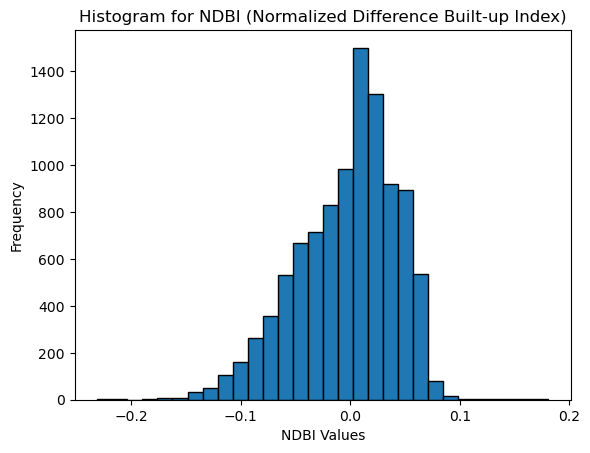

In [3]:
# Histogram for NDBI -> right skewed
ndbi_series = df["NDBI"]
plt.hist(ndbi_series, bins=30, edgecolor="black")
plt.xlabel("NDBI Values")
plt.ylabel("Frequency")
plt.title("Histogram for NDBI (Normalized Difference Built-up Index)")
plt.show()

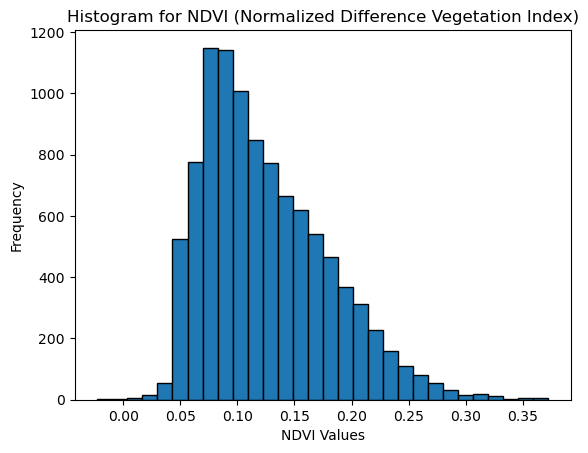

In [4]:
# Histogram for NDVI -> left skewed
ndvi_series = df["NDVI"]
plt.hist(ndvi_series, bins=30, edgecolor="black")
plt.xlabel("NDVI Values")
plt.ylabel("Frequency")
plt.title("Histogram for NDVI (Normalized Difference Vegetation Index)")
plt.show()

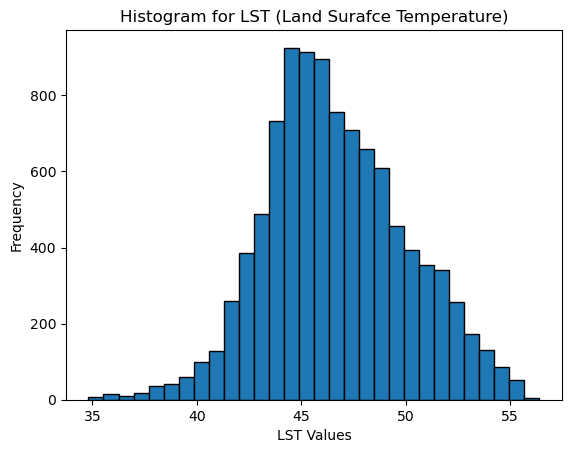

In [5]:
# Histogram LST
plt.hist(df["LST"], bins=30, edgecolor="black")
plt.title("Histogram for LST (Land Surafce Temperature)")
plt.xlabel("LST Values")
plt.ylabel("Frequency")
plt.show()

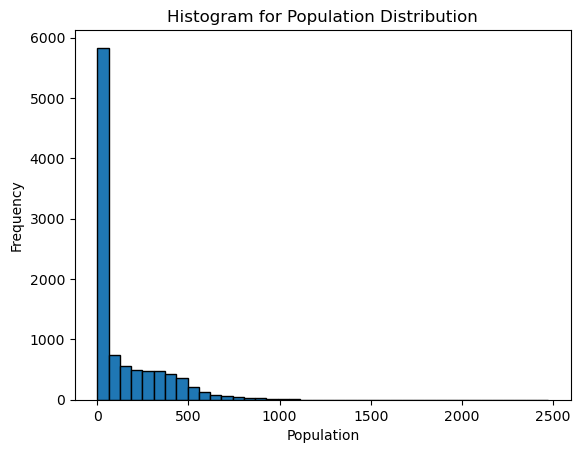

In [6]:
# Population Distribution
plt.hist(df["Population"], bins=40, edgecolor="black")
plt.xlabel("Population")
plt.ylabel("Frequency")
plt.title("Histogram for Population Distribution")
plt.show()

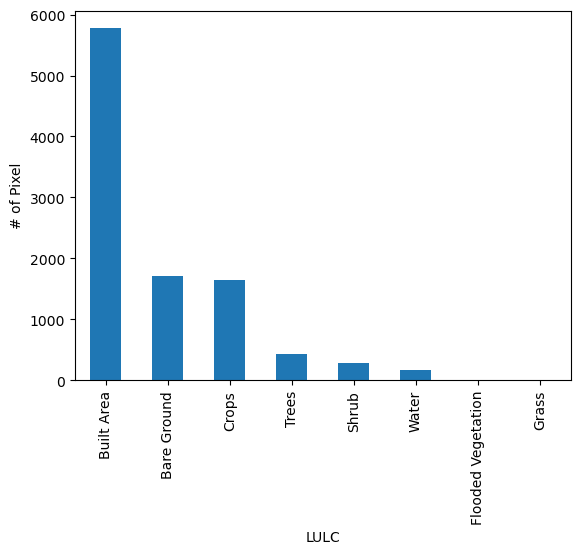

In [7]:
# Distribution for LULC
# plt.hist(df["LULC"], bins=30, edgecolor="black")
df["LULC_Name"].value_counts().plot(kind="bar")
plt.xlabel("LULC")
plt.ylabel("# of Pixel")
plt.xticks(rotation=90)
plt.show()

In [8]:
df_numeric = df.select_dtypes(include=np.number)
df_numeric.drop(["Latitude","Longitude"],axis=1)
corr = df_numeric.corr()

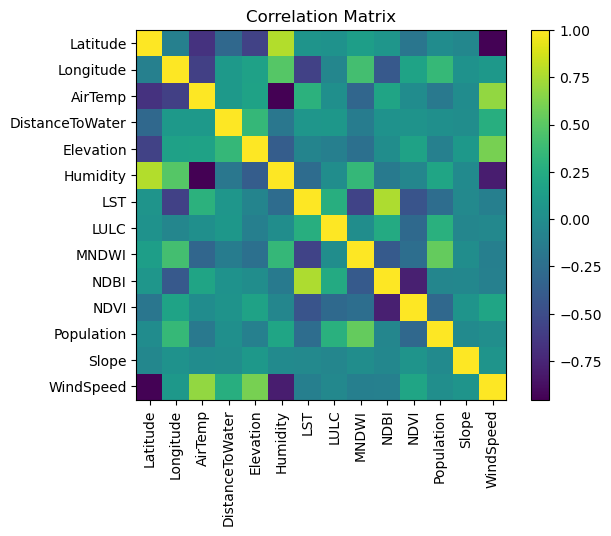

In [9]:
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.show()

In [10]:
features = ["LULC","MNDWI","NDBI","NDVI","Population","AirTemp","Elevation","Humidity","WindSpeed"]
df_numeric[features].corrwith(df_numeric["LST"])

LULC          0.270912
MNDWI        -0.557953
NDBI          0.755858
NDVI         -0.443553
Population   -0.256904
AirTemp       0.298838
Elevation    -0.068713
Humidity     -0.265986
WindSpeed    -0.107204
dtype: float64

In [11]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'LULC', 'MNDWI', 'NDBI', 'NDVI', 'Population',
       'Slope', 'WindSpeed', 'LULC_Name'],
      dtype='object')